# K-means para imágenes de galaxias

En este notebook aplicaremos método de k-means a galaxias del desafío Kaggle Galaxy Zoo

Basado en Machine learning for physics and Astronomy, Viviana Acquaviva (2023)


In [2]:
import numpy as np
import pandas as pd
import os
import random
import matplotlib.pyplot as plt

import skimage
from skimage.transform import resize, rescale
from skimage import io
from skimage.feature import blob_dog, blob_log, blob_doh # XD
from skimage.color import rgb2gray

Este conjunto de datos está compuesto por 200 imágenes seleccionadas al azar del desafío Kaggle Galaxy Zoo:

https://www.kaggle.com/c/galaxy-zoo-the-galaxy-challenge

El siguiente código visualiza los primeros 25 objetos en nuestro conjunto de datos. Podemos ejecutarlo para obtener una vista de las primeras 25 galaxias. Nota: es posible que reciba un mensaje de error, en este caso, consulte aquí

https://stackoverflow.com/questions/43288550/iopub-data-rate-exceeded-in-jupyter-notebook-when-viewing-image

Las imágenes que usaremos fueron procesadas para eliminar otras fuentes distintas a la central

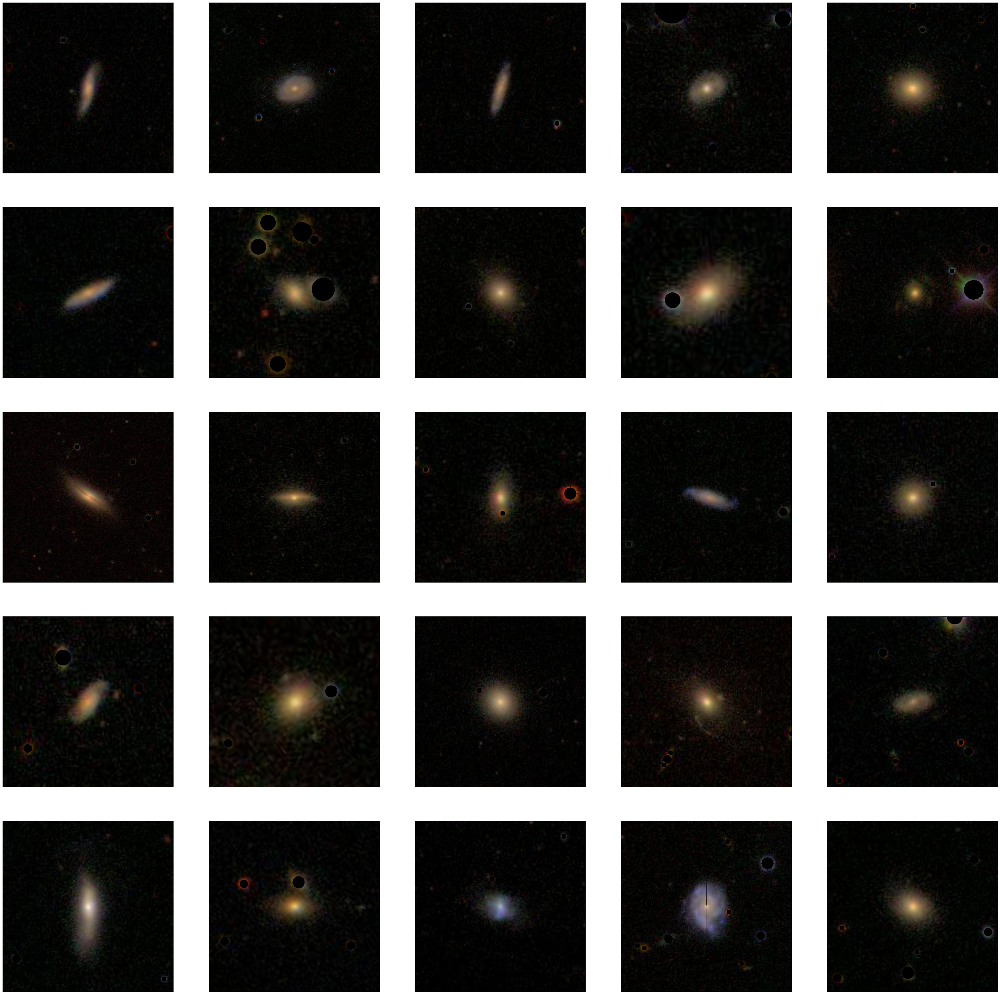

In [3]:
fig, axes = plt.subplots(ncols= 5, nrows = 5,figsize=(50,50))

ax = axes.ravel()

for i in range(ax.shape[0]):

    img = skimage.io.imread('data/NoSources_Images/NoSources_Image_'+str(i)+'.png')
    ax[i].imshow(img, cmap='gray')
    ax[i].set_xticks([])
    ax[i].set_yticks([])



In [4]:
images = []

for i in range(200):
    img =skimage.io.imread('data/NoSources_Images/NoSources_Image_'+str(i)+'.png')
    img_resized = resize(img,(100,100))
    length = np.prod(img_resized.shape)
    img_resized = np.reshape(img_resized,length)
    images.append(img_resized)

images = np.vstack(images)

In [12]:
images.shape

(200, 30000)

In [13]:
images

array([[0.00072045, 0.00072045, 0.00072045, ..., 0.04023101, 0.03631007,
        0.02847539],
       [0.00256149, 0.00923536, 0.00092913, ..., 0.01534901, 0.01534901,
        0.00853146],
       [0.01312521, 0.01312521, 0.01312521, ..., 0.02014842, 0.02014717,
        0.01261165],
       ...,
       [0.00229134, 0.01401319, 0.00168676, ..., 0.0106061 , 0.0106061 ,
        0.0106061 ],
       [0.03084319, 0.03084319, 0.02301529, ..., 0.02839959, 0.03232301,
        0.01433026],
       [0.01358463, 0.01358463, 0.01358463, ..., 0.01650169, 0.0241105 ,
        0.02018779]], shape=(200, 30000))

### Los datos no están etiquetados, por lo que usaremos K-Means para poder agruparlos.

Cuántos grupos cree que podemos encontrar en los datos? implemente K-means para esa cantidad

- `nclusters`: número de grupos
- `n_init`: controla cuántas veces K-means se ejecutará desde distintos puntos de inicio (semillas aleatorias).
Luego, se elige el resultado que tenga el menor error (es decir, el mejor agrupamiento).

**My guess:** probably around 4-5 groups, something like round/elliptical galaxies, spirals and small/irregular ones.

### Antes de fijar el número de grupos, probemos con el método del codo y silhouette score

Exception in thread Thread-5 (_readerthread):
Traceback (most recent call last):
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\Lib\threading.py", line 1045, in _bootstrap_inner
    self.run()
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\Lib\threading.py", line 982, in run
    self._target(*self._args, **self._kwargs)
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\Lib\subprocess.py", line 1599, in _readerthread
    buffer.append(fh.read())
                  ^^^^^^^^^
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\Lib\encodings\cp1252.py", line 23, in decode
    return codecs.charmap_decode(input,self.errors,decoding_table)[0]
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
UnicodeDecodeError: 'charmap' codec can't decode byte 0x81 in pos

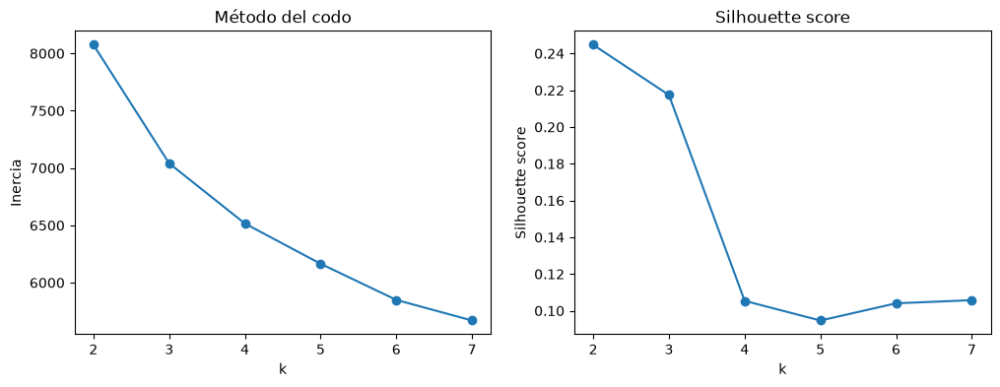

In [5]:
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans

inercias = []
silhouettes = []
rango_k = range(2, 8)

for k in rango_k:
    km = KMeans(n_clusters=k, n_init=10, random_state=10)
    etiquetas = km.fit_predict(images)
    inercias.append(km.inertia_)
    silhouettes.append(silhouette_score(images, etiquetas))

fig, axes = plt.subplots(1, 2, figsize=(12,4))
axes[0].plot(rango_k, inercias, 'o-')
axes[0].set_xlabel('k')
axes[0].set_ylabel('Inercia')
axes[0].set_title('Método del codo')

axes[1].plot(rango_k, silhouettes, 'o-')
axes[1].set_xlabel('k')
axes[1].set_ylabel('Silhouette score')
axes[1].set_title('Silhouette score')

plt.show()

Según estos gráficos, ¿qué valor de k elegirían?

The elbow plot doesn’t have a really sharp elbow, but the curve flattens out after k = 3. The silhouette score is highest for k = 2 (about 0.245) and still decent for k = 3 (about 0.22), but it drops a lot from k = 4 on. I chose k = 3 because it keeps a good silhouette score and gives a bit more detail than just two groups.

In [6]:
grupos=3  #ingrese acá el número de grupos

kmeans = KMeans(n_clusters=grupos, n_init=10, random_state = 10) # se inicializa el modelo
kmeans.fit(images) # se aplica a los datos
y_kmeans = kmeans.predict(images) # se generan las predicciones

In [7]:
y_kmeans # dependiendo de la cantidad de grupos que escogió, las predicciones son una etiqueta que indica a qué grupo pertenece, 0, 1, 2..... etc

array([1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1,
       1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 2, 0,
       1, 1, 1, 1, 2, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1,
       0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0,
       1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0,
       1, 1, 0, 1, 1, 1, 1, 0, 2, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1,
       1, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 2,
       1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1, 0, 1, 0,
       1, 1], dtype=int32)

In [8]:
print(len(np.where([y_kmeans == 1])[1])) # puede cambiar el valor para ver cuantos elementos hay por cada grupo

139


#### Podemos usar el código a continuación para observar 25 galaxias que fueron colocadas en cada  cluster y ver si tienen algún tipo de similitud.

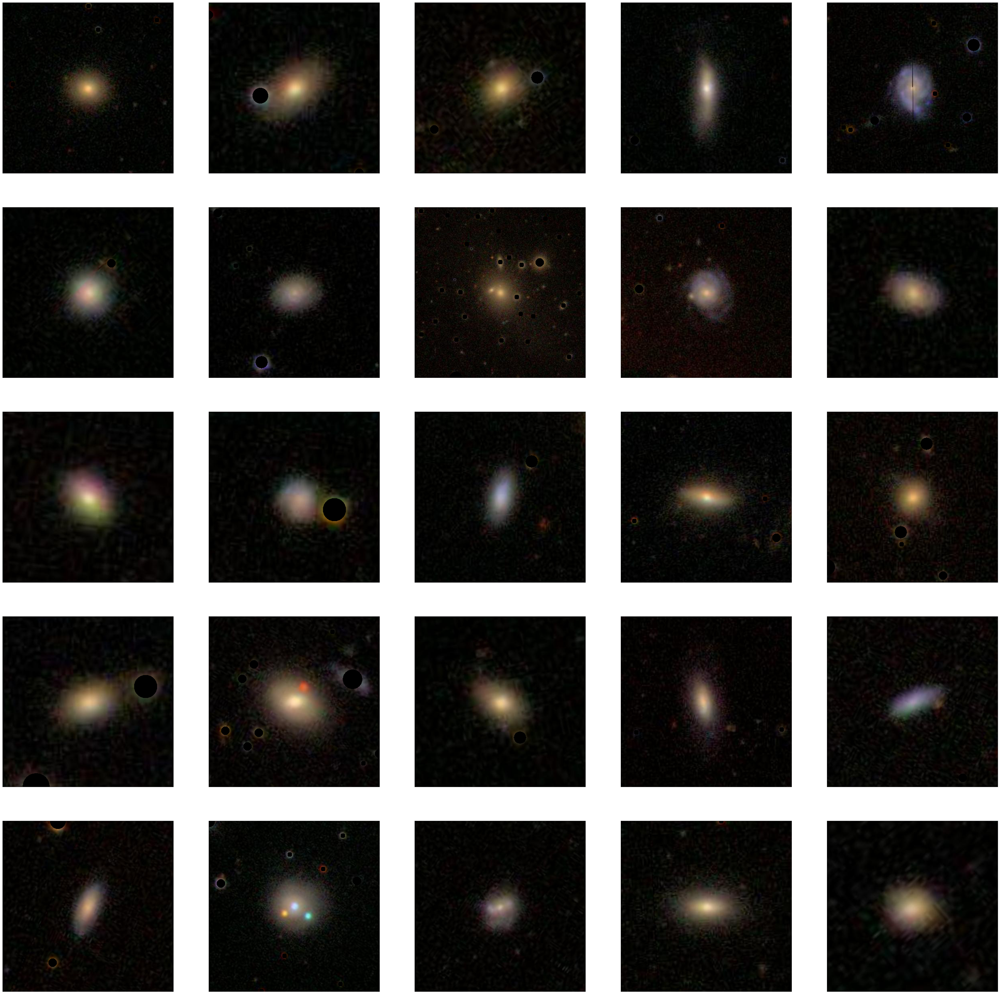

In [9]:
fig, axes = plt.subplots(ncols= 5, nrows = 5,figsize=(50,50))

ax = axes.ravel()

for i in range(min(len(np.where([y_kmeans == 0])[1]),25)):
    #la línea de abajo selecciona las galaxias que están asignadas al cluster 0.
    img = skimage.io.imread('data/NoSources_Images/NoSources_Image_'+str(np.where([y_kmeans == 0])[1][i])+'.png')
    ax[i].imshow(img, cmap='gray')
    ax[i].set_xticks([])
    ax[i].set_yticks([])

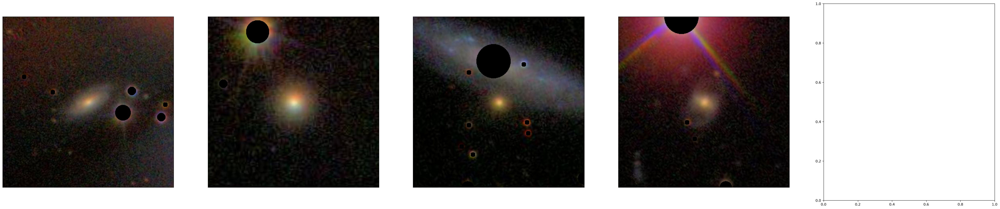

In [13]:
fig, axes = plt.subplots(ncols= 5, nrows = 1,figsize=(50,10))

ax = axes.ravel()

for i in range(min(len(np.where([y_kmeans == 2])[1]),25)):
    #la línea de abajo selecciona las galaxias que están asignadas al cluster 0.
    img = skimage.io.imread('data/NoSources_Images/NoSources_Image_'+str(np.where([y_kmeans == 2])[1][i])+'.png')
    ax[i].imshow(img, cmap='gray')
    ax[i].set_xticks([])
    ax[i].set_yticks([])

#### Verifique su resultado para cada cluster

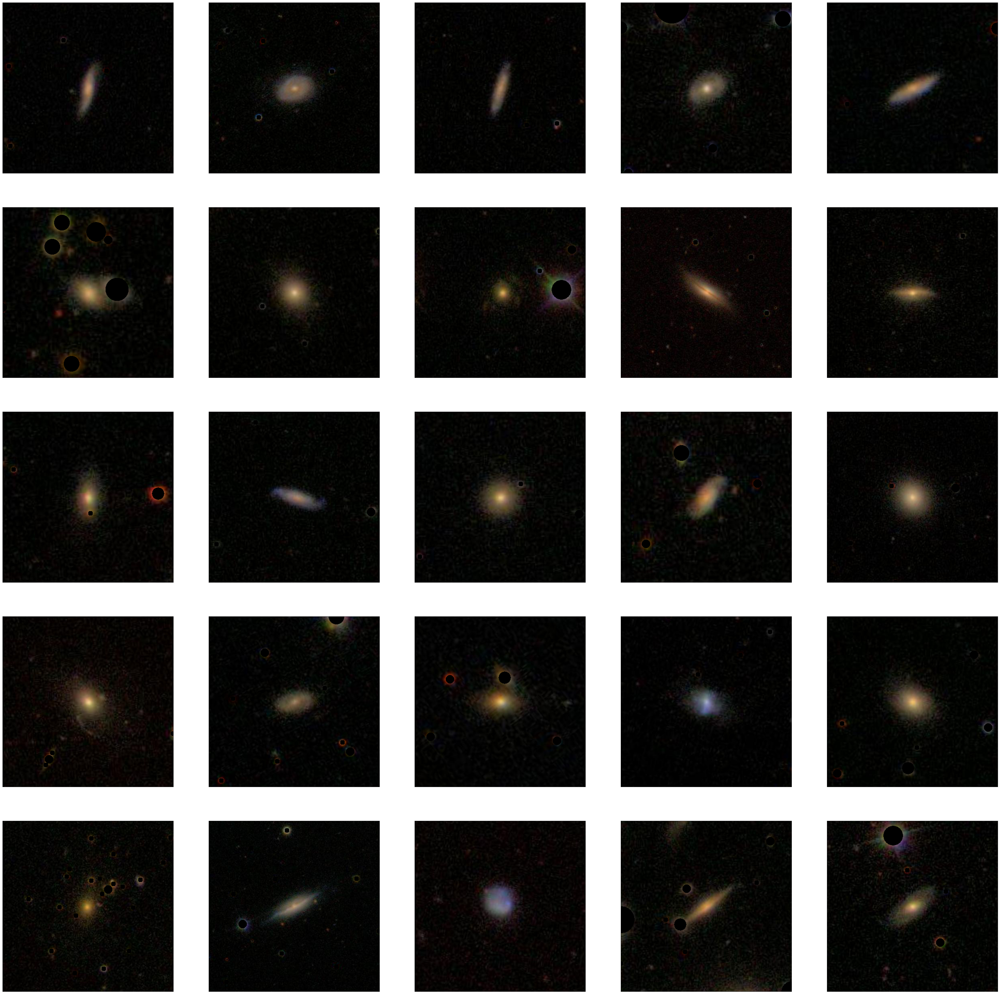

In [11]:
fig, axes = plt.subplots(ncols= 5, nrows = 5,figsize=(50,50))

ax = axes.ravel()

for i in range(min(len(np.where([y_kmeans == 1])[1]),25)):
    #la línea de abajo selecciona las galaxias que están asignadas al cluster 0.
    img = skimage.io.imread('data/NoSources_Images/NoSources_Image_'+str(np.where([y_kmeans == 1])[1][i])+'.png')
    ax[i].imshow(img, cmap='gray')
    ax[i].set_xticks([])
    ax[i].set_yticks([])

### Puede identificar algún criterio de separación de los grupos?



Cluster 0 has mostly round, face-on galaxies that look bigger and more diffuse (some bluish spirals too). Cluster 1 is mostly thin, elongated edge-on galaxies. Cluster 2 is really small (only 4 galaxies) and these are the images with big black masked circles and light spikes from bright stars, so here K-means basically grouped the artifacts and not the galaxy itself. So the main criterion seems to be shape / inclination and size of the galaxy, and the leftover masked regions from the star removal also have an effect.

### Probemos aplicando PCA antes de clusterizar

Si los clusters parecen agrupar más por brillo o tamaño que por forma, puede ser porque K-means sobre píxeles crudos usa distancia euclidiana, muy sensible a esas variables.

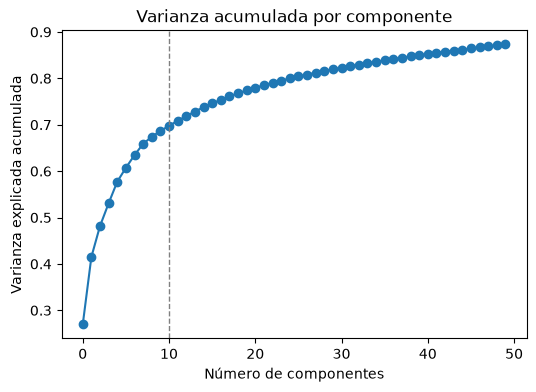

Varianza explicada con 10 componentes: 68.65%


In [12]:
from sklearn.decomposition import PCA

n_componentes = 10  # pruebe cambiar este número
pca = PCA(n_components=50, random_state=10)  # calculamos más para ver la curva completa
images_pca_full = pca.fit_transform(images)

plt.figure(figsize=(6,4))
plt.plot(np.cumsum(pca.explained_variance_ratio_), 'o-')
plt.axvline(n_componentes, color='gray', linestyle='--', linewidth=1)
plt.xlabel('Número de componentes')
plt.ylabel('Varianza explicada acumulada')
plt.title('Varianza acumulada por componente')
plt.show()

images_pca = images_pca_full[:, :n_componentes]  # nos quedamos con las primeras n_componentes
print(f"Varianza explicada con {n_componentes} componentes: {np.cumsum(pca.explained_variance_ratio_)[n_componentes-1]:.2%}")

In [14]:
kmeans_pca = KMeans(n_clusters=grupos, n_init=10, random_state=10)
y_kmeans_pca = kmeans_pca.fit_predict(images_pca)

comparacion = pd.crosstab(y_kmeans, y_kmeans_pca,
                          rownames=['Cluster (píxeles crudos)'],
                          colnames=['Cluster (PCA)'])
comparacion

Cluster (PCA),0,1,2
Cluster (píxeles crudos),,,
0,57,0,0
1,0,139,0
2,0,0,4


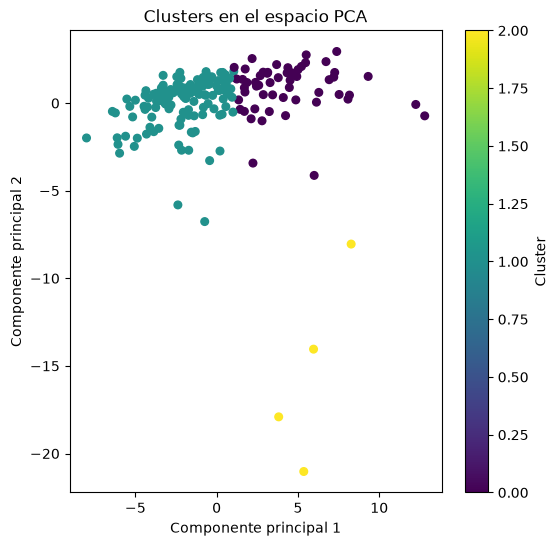

In [15]:
plt.figure(figsize=(6,6))
scatter = plt.scatter(images_pca[:,0], images_pca[:,1], c=y_kmeans_pca, cmap='viridis', s=30)
plt.xlabel('Componente principal 1')
plt.ylabel('Componente principal 2')
plt.title('Clusters en el espacio PCA')
plt.colorbar(scatter, label='Cluster')
plt.show()

#### Observemos algunas galaxias de los nuevos clusters (con PCA)

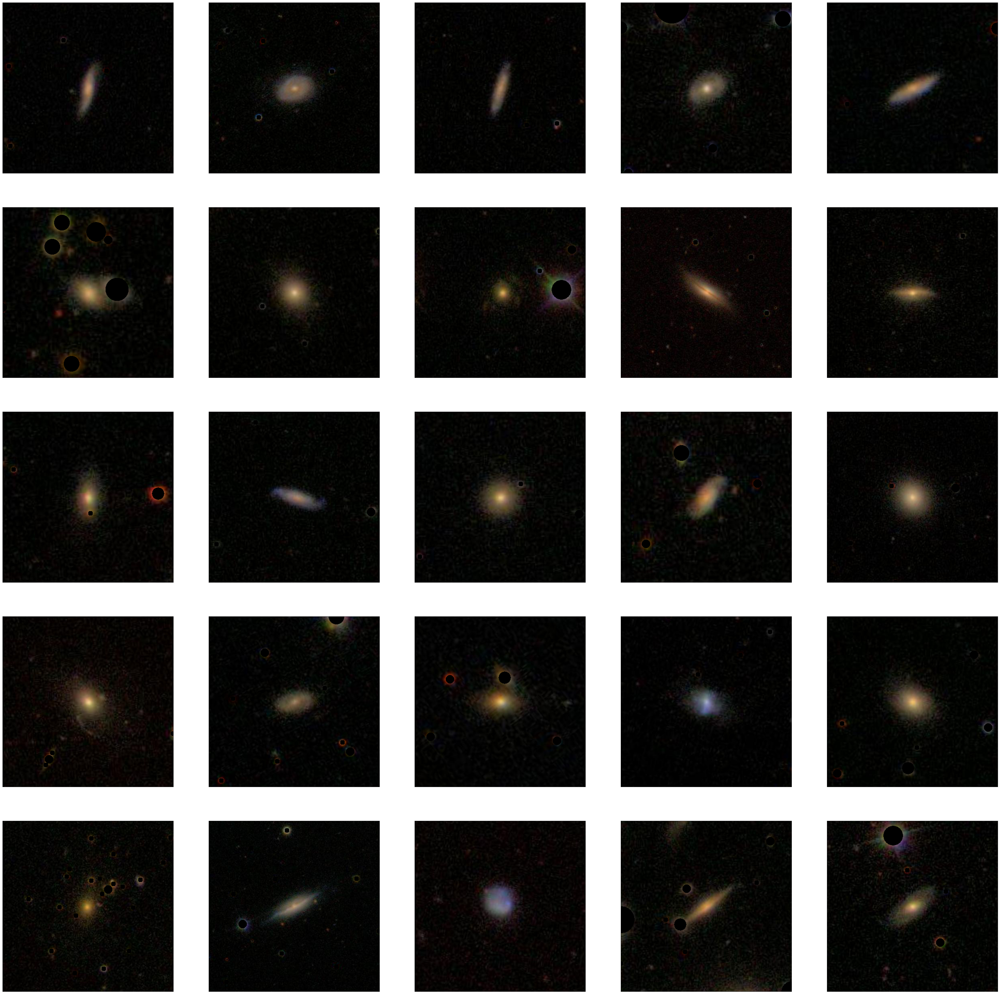

In [17]:
fig, axes = plt.subplots(ncols=5, nrows=5, figsize=(50,50))
ax = axes.ravel()

for i in range(min(len(np.where([y_kmeans_pca == 1])[1]),25)):
    img = skimage.io.imread('data/NoSources_Images/NoSources_Image_'+str(np.where([y_kmeans_pca == 1])[1][i])+'.png')
    ax[i].imshow(img, cmap='gray')
    ax[i].set_xticks([])
    ax[i].set_yticks([])

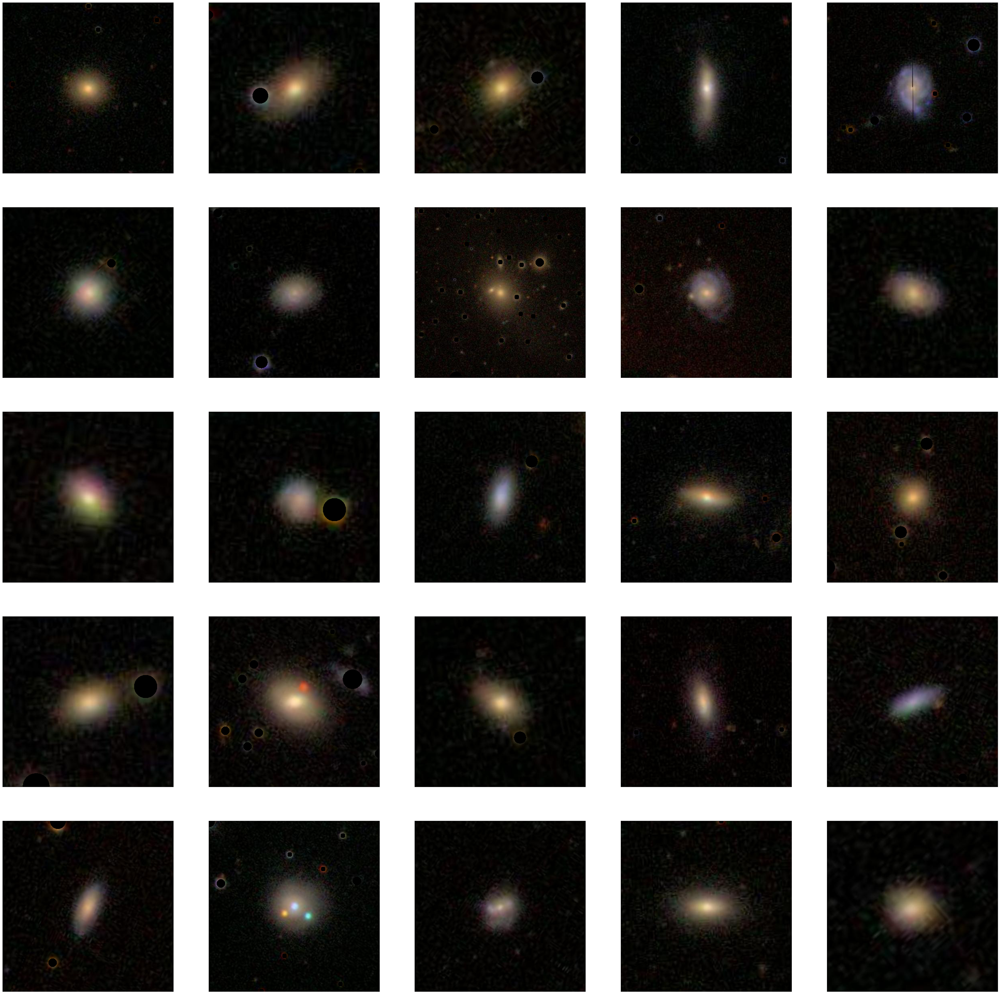

In [20]:
fig, axes = plt.subplots(ncols=5, nrows=5, figsize=(50,50))
ax = axes.ravel()

for i in range(min(len(np.where([y_kmeans_pca == 0])[1]),25)):
    img = skimage.io.imread('data/NoSources_Images/NoSources_Image_'+str(np.where([y_kmeans_pca == 0])[1][i])+'.png')
    ax[i].imshow(img, cmap='gray')
    ax[i].set_xticks([])
    ax[i].set_yticks([])

**¿Cambió el criterio de separación con PCA? Miren la tabla cruzada: ¿las mismas galaxias quedaron juntas en ambos métodos? ¿Qué les parece que capturan las primeras componentes principales?**

No, the criterion did not change. The crosstab is basically a diagonal (57, 139 and 4 galaxies), so exactly the same galaxies ended up together with both methods. This makes sense because 10 components already keep around 70% of the variance, so the main structure K-means found in the raw pixels is also the main structure in the PCA space.

In the scatter plot clusters 0 and 1 are separated mostly along PC1 (cluster 0 has the higher values), so PC1 probably captures the size / extension of the galaxy (big diffuse round ones vs. thin elongated ones). There is no clear gap between these two, it looks like K-means just cuts one continuous cloud in two. PC2 is what separates the 4 galaxies of cluster 2, which are the images with the big masked stars, so PC2 mostly captures those artifacts. PC1 explains about 27% of the variance and PC2 about 14%. Overall PCA did not give a better separation by shape here.